In [ ]:
# Bibliotecas generales
import numpy as np
import pandas as pd

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px


# Modelado y machine learning
from sklearn.cluster import KMeans

# Dask para procesamiento paralelo y escalable
import dask.dataframe as dd
import dask.array as da
import dask.bag as db
from dask_ml.preprocessing import StandardScaler

from dask_ml.model_selection import train_test_split
from lightgbm.dask import DaskLGBMClassifier
from dask_ml.model_selection import RandomizedSearchCV, train_test_split
from sklearn.metrics import make_scorer, f1_score
from scipy.stats import randint, uniform
from dask.distributed import wait
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from joblib import dump, load
%matplotlib inline  

# Conexion para trabajar en paralelo
**Nota:** Solo trabajaremos con dos computadores.
| Rol                        | Usuario   | ¿Scheduler? | ¿Worker? | N° de Workers | Hilos por Worker | RAM por Worker |
| -------------------------- | -------------- | --------- | ----------- | -------- | ------------- | ---------------- | 
| **Portátil** (`fabiansem`) | `fabian`  |  Sí        |  Sí     | 2             | 4                | 3.5 GB         |
| **Maestro**                | `maestro` |  No        |  Sí     | 2             | 2                | 12 GB          |


In [5]:
from dask.distributed import Client

client = Client('tcp://192.168.2.14:8786')

client

<Client: 'tcp://192.168.2.14:8786' processes=2 threads=8, memory=25.61 GiB>

Task exception was never retrieved
future: <Task finished name='Task-32' coro=<Client._gather.<locals>.wait() done, defined at /home/fabian/miniconda3/envs/dash_env/lib/python3.13/site-packages/distributed/client.py:2394> exception=AllExit()>
Traceback (most recent call last):
  File "/home/fabian/miniconda3/envs/dash_env/lib/python3.13/site-packages/distributed/client.py", line 2403, in wait
    raise AllExit()
distributed.client.AllExit


In [6]:
import os

file_size = os.path.getsize('/media/fabian/INFO/Universidad externado/ML2/parcial/data/data_preprocesada.parquet')
print(f"Tamaño archivo: {file_size / (1024**2):.5f} MB")

Tamaño archivo: 7.05044 MB


In [7]:
df = dd.read_parquet(
    '/home/shared_user/datasets/data_preprocesada.parquet',
    sep=',',
    assume_missing=True,
    low_memory=False,
    blocksize=None  # (lectura completa)
)
bool_cols = df.select_dtypes(bool).columns
df = df.assign(**{c: df[c].astype("int8") for c in bool_cols})

print(f"Particiones iniciales: {df.npartitions}")

# Luego forzar 8 particiones
df = df.repartition(npartitions=8)

print(f"Particiones después de reparticionar: {df.npartitions}")

Particiones iniciales: 1
Particiones después de reparticionar: 8


In [8]:
df.columns

Index(['arma_cat_ARMA_CORTANTE_OTRA', 'arma_cat_ARMA_DESCONOCIDA',
       'arma_cat_CUCHILLO_NAVAJA', 'arma_cat_ESTUPEFACIENTE',
       'arma_cat_FUERZA_CORPORAL', 'arma_cat_GOLPE_CONTUNDENTE',
       'arma_cat_PISTOLA', 'arma_cat_RIFLE_ESCOPETA',
       'arma_cat_SUSTANCIA_QUIMICA', 'premis_Comercial', 'premis_Educación',
       'premis_Entretenimiento', 'premis_Gobierno',
       'premis_Instalaciones Públicas', 'premis_Otros', 'premis_Religioso',
       'premis_Residencial', 'premis_Salud', 'premis_Transporte',
       'premis_Vía Pública', 'descent_ctx_Asiático', 'descent_ctx_Blanco',
       'descent_ctx_Camboyano', 'descent_ctx_Chino', 'descent_ctx_Coreano',
       'descent_ctx_Desconocido', 'descent_ctx_Filipino',
       'descent_ctx_Guamaniano', 'descent_ctx_Hawaiano',
       'descent_ctx_Hispano/Latino',
       'descent_ctx_Indio Americano/Alaska Nativa', 'descent_ctx_Japonés',
       'descent_ctx_Laosiano', 'descent_ctx_Negro/Afroamericano',
       'descent_ctx_No especificado',

In [11]:
# Ver el gráfico de tareas (depende de client ya conectado)
client.get_worker_logs()
client

<Client: 'tcp://192.168.2.14:8786' processes=2 threads=8, memory=25.61 GiB>

In [12]:
# Persistir el dataframe completo (lo carga en RAM distribuida)
df = df.persist()

# Hacer una operación para forzar trabajo distribuido
resultados = df.describe().compute() 
from dask.distributed import Client

client = Client('tcp://192.168.2.14:8786')

client

print(resultados)

       arma_cat_ARMA_CORTANTE_OTRA  arma_cat_ARMA_DESCONOCIDA  \
count                 1.004989e+06               1.004989e+06   
mean                  1.234839e-03               7.106416e-01   
std                   3.511860e-02               4.534648e-01   
min                   0.000000e+00               0.000000e+00   
25%                   0.000000e+00               1.000000e+00   
50%                   0.000000e+00               1.000000e+00   
75%                   0.000000e+00               1.000000e+00   
max                   1.000000e+00               1.000000e+00   

       arma_cat_CUCHILLO_NAVAJA  arma_cat_ESTUPEFACIENTE  \
count              1.004989e+06             1.004989e+06   
mean               2.553461e-02             2.911773e-02   
std                1.577422e-01             1.681366e-01   
min                0.000000e+00             0.000000e+00   
25%                0.000000e+00             0.000000e+00   
50%                0.000000e+00             0.000000e+

In [ ]:
df.dtypes

arma_cat_ARMA_CORTANTE_OTRA                             int8
arma_cat_ARMA_DESCONOCIDA                               int8
arma_cat_CUCHILLO_NAVAJA                                int8
arma_cat_ESTUPEFACIENTE                                 int8
arma_cat_FUERZA_CORPORAL                                int8
arma_cat_GOLPE_CONTUNDENTE                              int8
arma_cat_PISTOLA                                        int8
arma_cat_RIFLE_ESCOPETA                                 int8
arma_cat_SUSTANCIA_QUIMICA                              int8
premis_Comercial                                        int8
premis_Educación                                        int8
premis_Entretenimiento                                  int8
premis_Gobierno                                         int8
premis_Instalaciones Públicas                           int8
premis_Otros                                            int8
premis_Religioso                                        int8
premis_Residencial      

In [ ]:
df['lat_rad'].head()

0    0.597119
1    0.596890
2    0.596636
3    0.594004
4    0.593086
Name: lat_rad, dtype: float64

In [ ]:
df['lon_rad'].head()

0   -2.066630
1   -2.066824
2   -2.067358
3   -2.066028
4   -2.067081
Name: lon_rad, dtype: float64

In [ ]:
df['Vict Age'].head()

0    31
1    32
2    30
3    47
4    63
Name: Vict Age, dtype: int64

**Nota:** convertimos las columnas a float32 para ahorrar memoria, y obligamos a los workers a que trabajen en paralelo, le damos partes del dataset para que trabajen

In [13]:
from dask_ml.preprocessing import LabelEncoder

# Instanciar encoder Dask ML
le = LabelEncoder()

# Ajustar y transformar la serie `target`
# (se mantiene como Dask Series).
y_encoded = le.fit_transform(df["target"])

# Sustituir la columna original
df = df.assign(target=y_encoded)

# (opcional) persistir si vas a entrenar enseguida
df = df.persist()

# Verificación rápida
print(df["target"].head())          # ahora es int

/home/fabian/miniconda3/envs/dash_env/lib/python3.13/site-packages/dask/dataframe/dask_expr/_collection.py:1430: UserWarning: Dask currently has limited support for converting pandas extension dtypes to arrays. Converting string to object dtype.
  warnings.warn(


0    5
1    0
2    5
3    9
4    9
Name: target, dtype: int64


In [14]:
# ------ columnas que sí son float y SÍ queremos a float32 ------
float_cols = ["year_occ_z", "lat_rad", "lon_rad", "Vict Age", "target"]

# cast dentro de Dask (vectorizado y perezoso)
df[float_cols] = df[float_cols].astype("float32")

# Particionar antes, si es necesario
if df.npartitions == 1:
    df = df.repartition(npartitions=2)

print(df.dtypes)   # compruebas cambios


arma_cat_ARMA_CORTANTE_OTRA                     int8
arma_cat_ARMA_DESCONOCIDA                       int8
arma_cat_CUCHILLO_NAVAJA                        int8
arma_cat_ESTUPEFACIENTE                         int8
arma_cat_FUERZA_CORPORAL                        int8
arma_cat_GOLPE_CONTUNDENTE                      int8
arma_cat_PISTOLA                                int8
arma_cat_RIFLE_ESCOPETA                         int8
arma_cat_SUSTANCIA_QUIMICA                      int8
premis_Comercial                                int8
premis_Educación                                int8
premis_Entretenimiento                          int8
premis_Gobierno                                 int8
premis_Instalaciones Públicas                   int8
premis_Otros                                    int8
premis_Religioso                                int8
premis_Residencial                              int8
premis_Salud                                    int8
premis_Transporte                             

In [ ]:
df['lat_rad'].head()

0    0.597119
1    0.596890
2    0.596636
3    0.594004
4    0.593086
Name: lat_rad, dtype: float32

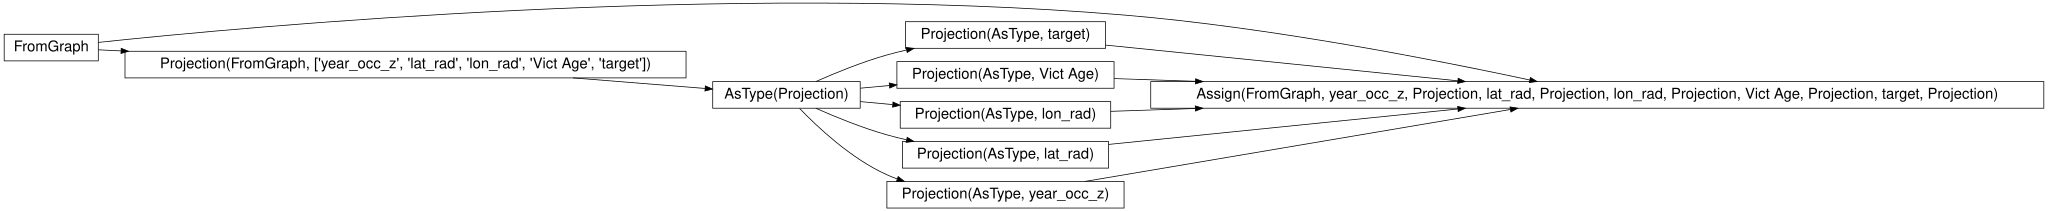

In [15]:
#Esto muestra los como se conectan las tareas internas
df.visualize(rankdir="LR")  # Requiere Graphviz

- $1^{\text{er}}$ split (70 % / 30 %) – deja aparte un bloque grande `X_tmp`, `y_tmp`.

- $2^{\text{do}}$ split (50 % / 50 % sobre `X_tmp`) – lo parte a la mitad ⇒ 15 % validación, 15 % test.

Así evitas leer el set dos veces y la proporción final queda: **(70 / 15 / 15)**.


Al no estratificar, Dask simplemente baraja las filas y corta; con 1 M de registros la distribución de clases típica varía < 0.5 pp.

In [ ]:
# --- quitamos stratify ---
X_train, X_tmp, y_train, y_tmp = train_test_split(
    df.drop("target", axis=1),
    df["target"],
    test_size=0.30,       # 30 % = 15 % val + 15 % test
    shuffle=True,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_tmp, y_tmp,
    test_size=0.50,       # la mitad de ese 30 % → 15 %
    shuffle=True,
    random_state=42
)
print("train:\n", y_train.value_counts(normalize=True).compute().head())
print("test:\n",  y_test.value_counts(normalize=True).compute().head())


train:
 target
6.0     0.001574
10.0    0.001379
2.0     0.008937
3.0     0.123160
0.0     0.156473
Name: proportion, dtype: float64
test:
 target
6.0     0.001658
10.0    0.001273
2.0     0.009150
3.0     0.120302
0.0     0.157797
Name: proportion, dtype: float64


## LightGBM con Dask. 
### esta primeras partes no funciono ninguna, porque el metodo RandomizedSearchCV nunca convergio 
**Funciono solo sino se usa el  RandomizedSearchCV**
requiere menos computo que XGboost

### modelo base

In [ ]:
lgb = DaskLGBMClassifier(
    objective="multiclass",
    num_class=y_train.unique().compute().size,
    n_estimators=100,
    learning_rate=0.1,
    class_weight="balanced",
    tree_learner="data",      # mejor para clusters pequeños
    n_jobs=-1,
    random_state=42,
)

## espacio de búsqueda
**Nota:** Se bajo los parametros 3 veces, por temas de tiempo, se descarta y se usara solamente el 50% de la muestra que sea representativa

In [ ]:
param_dist = {
    "num_leaves": [31, 63],
    "max_depth": [-1, 10],
    "subsample": [0.8],
    "colsample_bytree": [0.8],
    "reg_lambda": [0.0, 1.0],
}


search = RandomizedSearchCV(
    estimator=lgb,
    param_distributions=param_dist,
    n_iter=12,
    scoring=make_scorer(f1_score, average="macro"),
    cv=1, #sin k-fold
    random_state=42,
)



In [ ]:
search.fit(X_train, y_train)

print("Mejores hiper-parámetros:", search.best_params_)
print("F1-macro (CV):", search.best_score_)

In [ ]:
from sklearn.metrics import classification_report, f1_score

# Usamos el mejor modelo entrenado
model = search.best_estimator_

# Predecimos sobre el conjunto de validación
y_val_pred = model.predict(X_val)

# Evaluamos F1 macro (lo que estás usando como métrica)
f1 = f1_score(y_val.compute(), y_val_pred.compute(), average='macro')
print(f"F1-macro en VALIDACIÓN: {f1:.4f}")

# Informe detallado por clase
print(classification_report(y_val.compute(), y_val_pred.compute()))


In [ ]:
# Reunir todos los datos disponibles para entrenamiento
X_final = dd.concat([X_train, X_val])
y_final = dd.concat([y_train, y_val])

# Entrenar con los mejores parámetros
final_model = DaskLGBMClassifier(**search.best_params_)
final_model.fit(X_final, y_final)


In [ ]:
y_test_pred = final_model.predict(X_test)

print("F1-macro en TEST:", f1_score(y_test.compute(), y_test_pred.compute(), average='macro'))
print(classification_report(y_test.compute(), y_test_pred.compute()))


In [ ]:
import joblib

# Guardar solo los parámetros
joblib.dump(search.best_params_, "best_params_lightgbm.pkl")

# Si usas scikit-learn API de LGBM, puedes guardar el modelo completo (no el de Dask)
model_local = model.to_local()
joblib.dump(model_local, "modelo_final_lightgbm.pkl")


In [ ]:
local_model = final_model.to_local()

importances = local_model.feature_importances_
cols = X_final.columns

df_importance = pd.DataFrame({
    "feature": cols,
    "importance": importances
}).sort_values(by="importance", ascending=False)

# Gráfico
df_importance.head(20).plot.barh(x="feature", y="importance", figsize=(10, 8), legend=False)
plt.title("Importancia de variables (Top 20)")
plt.tight_layout()
plt.show()


## Con una muestra del 50% y del 5% de los datos
RandomizedSearchCV

In [ ]:
# Toma el 50 % del DataFrame total, con shuffle activado
df_sample = df.sample(frac=0.05, random_state=42).persist()


In [ ]:
# Suponiendo que target tiene ≤ 20 clases distintas
classes = df["target"].unique().compute()

samples = []
for c in classes:
    group = df[df["target"] == c]
    group_sample = group.sample(frac=0.5, random_state=42)
    samples.append(group_sample)

df_sample = dd.concat(samples).persist()


In [ ]:
# --- quitamos stratify ---
X_train, X_tmp, y_train, y_tmp = train_test_split(
    df_sample.drop("target", axis=1),
    df_sample["target"],
    test_size=0.30,       # 30 % = 15 % val + 15 % test
    shuffle=True,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_tmp, y_tmp,
    test_size=0.50,       # la mitad de ese 30 % → 15 %
    shuffle=True,
    random_state=42
)


modificamos los parametros ya que aunque bajamos el tamaño de la muestra, le cuesta a los computadores converger y llegar a una respuesta.

In [ ]:
from lightgbm.dask import DaskLGBMClassifier
from dask_ml.model_selection import RandomizedSearchCV
from sklearn.model_selection import ShuffleSplit
from sklearn.metrics import make_scorer, f1_score
from dask.distributed import wait          # ← for sync

In [ ]:
#lgb = DaskLGBMClassifier(
#    objective="multiclass",
#    num_class=y_train.unique().compute().size,
#    n_estimators=100,
#    learning_rate=0.1,
#    class_weight="balanced",
#    tree_learner="data",      # mejor para clusters pequeños
#    n_jobs=-1,
#    random_state=42,
#)

lgb = DaskLGBMClassifier(
    objective="multiclass",
    num_class=y_train.nunique().compute(),
    n_estimators=8,                # ↓ 100 → 60
    learning_rate=0.15,            # un poco + alto
    early_stopping_rounds=30,      # corta entrenos largos
    tree_learner="data",
    class_weight="balanced",
    n_jobs=-1,
    random_state=42,
)

## No funciono, nunca convergio, duro 4 horas y nada y con el 5% de la muestra

In [ ]:
# Toma el 50 % del DataFrame total, con shuffle activado
df_sample = df.sample(frac=0.05, random_state=42).persist()

In [ ]:
# --- quitamos stratify ---
X_train, X_tmp, y_train, y_tmp = train_test_split(
    df_sample.drop("target", axis=1),
    df_sample["target"],
    test_size=0.30,       # 30 % = 15 % val + 15 % test
    shuffle=True,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_tmp, y_tmp,
    test_size=0.50,       # la mitad de ese 30 % → 15 %
    shuffle=True,
    random_state=42
)

In [18]:
param_dist = {
    "num_leaves": [31, 63],
    "max_depth": [-1, 10],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8],
    "reg_lambda": [0.0, 1.0],
}

cv_split = ShuffleSplit(n_splits=2, test_size=0.2, random_state=42)

search = RandomizedSearchCV(
    lgb,
    param_distributions=param_dist,
    n_iter=8,                       # ↓ 12 → 8
    scoring=make_scorer(f1_score, average="macro"),
    cv=cv_split,
    random_state=42,
    n_jobs=-1                       # distribuye folds en workers
)

search.fit(X_train, y_train)
best_model = search.best_estimator_
wait(best_model.fitted_)            # asegúrate de que terminó

NameError: name 'ShuffleSplit' is not defined

## intento pero sin ese metodo (si funciono)

In [45]:
# Toma el 50 % del DataFrame total, con shuffle activado
df_sample = df.sample(frac=0.50, random_state=42).persist()

In [46]:
X_train, X_tmp, y_train, y_tmp = train_test_split(
    df_sample.drop("target", axis=1),
    df_sample["target"],
    test_size=0.30,       # 30 % = 15 % val + 15 % test
    shuffle=True,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_tmp, y_tmp,
    test_size=0.50,       # la mitad de ese 30 % → 15 %
    shuffle=True,
    random_state=42
)

In [47]:
# Definir modelo con hiperparámetros razonables
modelo = DaskLGBMClassifier(
    num_leaves=70,
    max_depth=-1,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    random_state=42
)

# Entrenar
modelo.fit(X_train, y_train)
wait(modelo.fitted_)

/home/fabian/miniconda3/envs/dash_env/lib/python3.13/site-packages/lightgbm/dask.py:549: UserWarning: Parameter n_jobs will be ignored.
  _log_warning(f"Parameter {param_alias} will be ignored.")


Finding random open ports for workers


DoneAndNotDoneFutures(done=set(), not_done=set())

In [48]:
# Predecir y evaluar en validación
y_val_pred = modelo.predict(X_val).compute()
y_val_true = y_val.compute()

print("Evaluación en conjunto de validación:")
print(classification_report(y_val_true, y_val_pred))


/home/fabian/miniconda3/envs/dash_env/lib/python3.13/site-packages/distributed/client.py:3383: UserWarning: Sending large graph of size 10.40 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


Evaluación en conjunto de validación:
              precision    recall  f1-score   support

         0.0       0.62      0.77      0.69     11705
         1.0       0.44      0.46      0.45     10873
         2.0       0.61      0.64      0.63       690
         3.0       0.82      0.94      0.87      9191
         4.0       0.38      0.07      0.12      1029
         5.0       0.41      0.57      0.48      6231
         6.0       0.15      0.03      0.05       122
         7.0       0.63      0.19      0.29       227
         8.0       0.48      0.21      0.30      9721
         9.0       0.46      0.52      0.49     14027
        10.0       0.00      0.00      0.00       108
        11.0       0.44      0.26      0.32      4900
        12.0       0.41      0.15      0.22      1068
        13.0       0.58      0.57      0.57      5517

    accuracy                           0.54     75409
   macro avg       0.46      0.39      0.39     75409
weighted avg       0.53      0.54      0.5

In [91]:
modelo_local = modelo.to_local()          # convierte Dask → local
dump(modelo_local, "dask_lgbm_sample.pkl")
print("Modelo completo guardado en dask_lgbm_sample.pkl")

Modelo completo guardado en dask_lgbm_sample.pkl


In [93]:
from joblib import load
modelo_recargado = load("dask_lgbm_sample.pkl")
y_pred = modelo_recargado.predict(X_test)


# RidgeClassifier dask, (no se puede)
**Porque:**
dask-ml solo implementó IncrementalPCA para trabajar con dask.array, no con
dask.dataframe

In [ ]:
# Codigo
from dask_ml.model_selection import train_test_split
from dask_ml.metrics import accuracy_score, mean_squared_error


In [ ]:
# Toma el 50 % del DataFrame total, con shuffle activado
df_sample = df.sample(frac=0.20, random_state=42).persist()

In [ ]:
#X_train, X_tmp, y_train, y_tmp = train_test_split(
#    df_sample.drop("target", axis=1),
#    df_sample["target"],
#    test_size=0.30,
#    shuffle=True,
#    random_state=42
#)
#X_val, X_test, y_val, y_test = train_test_split(
#    X_tmp, y_tmp,
#    test_size=0.50,
#    shuffle=True,
#    random_state=42
#)

#print("train:\n", y_train.value_counts(normalize=True).compute().head())
#print("test:\n",  y_test.value_counts(normalize=True).compute().head())

## PCA con el train

In [ ]:
#from dask_ml.decomposition import IncrementalPCA

#pca = IncrementalPCA(n_components=100)   # o n_components=None + .explained_variance_ratio_

# ¡Sólo el entrenamiento!
#X_train_pca = pca.fit_transform(X_train)

# aplicar después (‘inference’) a val y test
#X_val_pca  = pca.transform(X_val)
#X_test_pca = pca.transform(X_test)

In [ ]:
#from sklearn.linear_model import RidgeClassifier

#clf = RidgeClassifier(alpha=1.0)          # se entrena en memoria local
#clf.fit(X_train_pca.compute(), y_train.compute())

#preds = clf.predict(X_val_pca.compute())


# Sin computacion distribuida

In [82]:
# Leer el Parquet
df = pd.read_parquet(
    '/home/shared_user/datasets/data_preprocesada.parquet'
)

# Convertir las columnas booleanas (las dummies) a int8
bool_cols = df.select_dtypes(include='bool').columns
df[bool_cols] = df[bool_cols].astype('int8')

# Label‐encode de la columna target
le = LabelEncoder()
df['target'] = le.fit_transform(df['target'])

# Reparticionar → N/A en pandas (todo en memoria)

# Cast de ciertas columnas float a float32
float_cols = ["year_occ_z", "lat_rad", "lon_rad", "Vict Age", "target"]
df[float_cols] = df[float_cols].astype('float32')



In [83]:
# Split estratificado: 70% train, 15% val, 15% test
X = df.drop(columns="target")
y = df["target"]

# Primero separamos 70% train y 30% tmp
X_train, X_tmp, y_train, y_tmp = train_test_split(
    X, y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

# De ese 30%, la mitad a val y la otra mitad a test = 15% cada uno
X_val, X_test, y_val, y_test = train_test_split(
    X_tmp, y_tmp,
    test_size=0.50,
    stratify=y_tmp,
    random_state=42
)

print("Shapes:", X_train.shape, X_val.shape, X_test.shape)

Shapes: (703492, 53) (150748, 53) (150749, 53)


In [85]:
X_train = X_train.fillna(0)
X_val   = X_val.fillna(0)
X_test  = X_test.fillna(0)

In [94]:
# Logistic Regression con L2
lr_l2 = LogisticRegression(
    penalty='l2',
    solver='saga',
    C=1.0,
    max_iter=1000,
    n_jobs=-1,
    random_state=42
)
lr_l2.fit(X_train, y_train)
y_val_pred_l2 = lr_l2.predict(X_val)
print("=== Validación L2 ===")
print(classification_report(y_val, y_val_pred_l2))

# Logistic Regression con L1
lr_l1 = LogisticRegression(
    penalty='l1',
    solver='saga',
    C=1.0,
    max_iter=1000,
    n_jobs=-1,
    random_state=42
)

lr_l1.fit(X_train, y_train)
y_val_pred_l1 = lr_l1.predict(X_val)
print("=== Validación L1 ===")
print(classification_report(y_val, y_val_pred_l1))

# Elige el mejor (ejemplo: L2) y evalúa en test
best_model = lr_l2  # o lr_l1 si L1 fue mejor
y_test_pred = best_model.predict(X_test)
print("=== Test final ===")
print(classification_report(y_test, y_test_pred))

=== Validación L2 ===
              precision    recall  f1-score   support

         0.0       0.58      0.78      0.67     23625
         1.0       0.33      0.32      0.32     21701
         2.0       0.44      0.26      0.33      1353
         3.0       0.82      0.94      0.88     18468
         4.0       0.28      0.01      0.01      2024
         5.0       0.34      0.52      0.41     12206
         6.0       0.00      0.00      0.00       242
         7.0       0.89      0.07      0.13       456
         8.0       0.35      0.13      0.19     19595
         9.0       0.40      0.48      0.44     27933
        10.0       0.00      0.00      0.00       208
        11.0       0.33      0.20      0.25      9945
        12.0       0.88      0.00      0.01      2187
        13.0       0.51      0.51      0.51     10805

    accuracy                           0.48    150748
   macro avg       0.44      0.30      0.30    150748
weighted avg       0.47      0.48      0.45    150748



/home/fabian/miniconda3/envs/dash_env/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/fabian/miniconda3/envs/dash_env/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/fabian/miniconda3/envs/dash_env/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.

=== Validación L1 ===
              precision    recall  f1-score   support

         0.0       0.58      0.78      0.67     23625
         1.0       0.33      0.32      0.32     21701
         2.0       0.44      0.26      0.33      1353
         3.0       0.82      0.94      0.88     18468
         4.0       0.28      0.01      0.01      2024
         5.0       0.34      0.52      0.41     12206
         6.0       0.00      0.00      0.00       242
         7.0       0.89      0.07      0.13       456
         8.0       0.35      0.13      0.19     19595
         9.0       0.40      0.48      0.44     27933
        10.0       0.00      0.00      0.00       208
        11.0       0.33      0.20      0.25      9945
        12.0       0.88      0.00      0.01      2187
        13.0       0.51      0.51      0.51     10805

    accuracy                           0.48    150748
   macro avg       0.44      0.30      0.30    150748
weighted avg       0.47      0.48      0.45    150748

===

/home/fabian/miniconda3/envs/dash_env/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/fabian/miniconda3/envs/dash_env/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/fabian/miniconda3/envs/dash_env/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.

In [95]:
from joblib import dump

# Guarda el modelo ganador (best_model)
dump(best_model, "logreg_best.pkl")

# (opcional) guardar también el LabelEncoder si lo necesitas
# dump({"model": best_model, "label_encoder": le}, "logreg_with_encoder.pkl")


['logreg_best.pkl']